[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/01-problem-framing.ipynb)

# Problem Framing and Success Metrics

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Turn a vague business request into a precisely defined prediction task.</li>
<li>Build a point-in-time label for one snapshot date and read its base rate.</li>
<li>Recognise a leaky feature and explain why it flatters a model.</li>
<li>Choose an evaluation metric that matches how the prediction will actually be used.</li>
</ul>
</div>

**Prerequisites:** <a href="../../getting-started/datasets/">The Datasets</a>. **Dataset:** Online Retail II. **Time:** about 30 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The retailer sells gift-ware, mostly to repeat buyers and wholesalers. In this teaching scenario (the retailer and its data are real; the account-manager story is ours), a handful of **account managers** phone customers to keep them buying. They can only make a limited number of calls each cycle, and the business has asked:

> *"Tell us which customers we are about to lose."*

That sentence cannot be turned into a model yet. *Lose* by when? *Which* customers (everyone who ever bought)? And what will anyone **do** with the answer? Most failed ML projects fail here, before a line of modelling code is written, because the problem was never pinned down.

## From wish to prediction task

Every prediction task needs six decisions. Writing them down first is the most valuable ten minutes in a project.

| Decision | Our choice | Why |
|---|---|---|
| **Action** | Account managers phone the customers most at risk | Capacity is limited, so we need a *ranking*, not just a yes/no |
| **Unit of prediction** | One customer **at one snapshot date** | The same customer can be safe in March and at risk in June, so each (customer, date) is its own example |
| **Population** | Customers who bought at least once in the 365 days before the snapshot | You cannot "lose" someone who already left long ago |
| **Event** | The customer places a genuine invoice again | Observable, no opinions involved |
| **Horizon** | 90 days after the snapshot | Justified from the data, right below |
| **Snapshot ("cutoff")** | A date; features see only the past, the label sees only the future | This is the line that prevents leakage |

### Load the data

We cleaned the raw file properly in a later page (*Cleaning*). Here we use the course's cleaned version so we can stay focused on framing.

In [2]:
cleaned = retail.clean_retail(load_retail())
sales, returns = cleaned.sales, cleaned.returns
inv = retail.invoices(sales)          # one row per invoice
print(f"{len(sales):,} purchase lines, {len(inv):,} invoices, {inv['customer_id'].nunique():,} customers")
inv.head()

788,187 purchase lines, 36,594 invoices, 5,852 customers


,customer_id,invoice,date,revenue,items,country
0,12346,499763,2010-03-02 13:08:00,27.05,5,United Kingdom
1,12346,513774,2010-06-28 13:53:00,142.31,19,United Kingdom
2,12346,541431,2011-01-18 10:01:00,"77,183.60",74215,United Kingdom
3,12347,529924,2010-10-31 14:20:00,611.53,509,Iceland
4,12347,537626,2010-12-07 14:57:00,711.79,319,Iceland


### Is 90 days a sensible horizon?

A horizon should come from how customers actually behave, not from a round number. How long do customers normally wait between orders?

27,026 gaps between consecutive order days
gap quantiles (days): {0.25: 13, 0.5: 32, 0.75: 70, 0.9: 148}
share of gaps that are 90 days or shorter: 81%


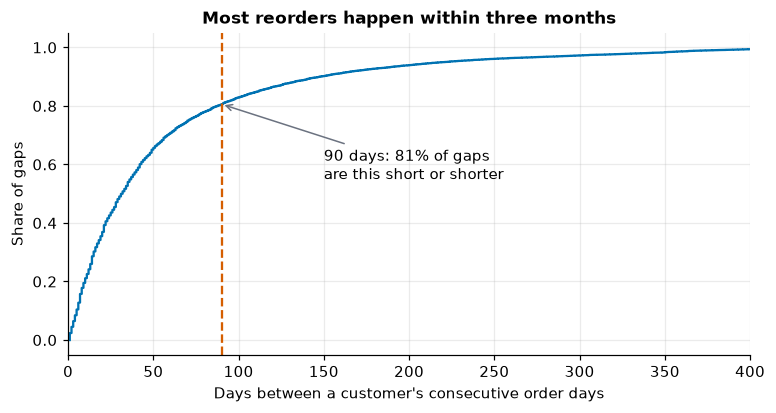

In [3]:
inv = inv.sort_values(["customer_id", "date"])
day = inv["date"].dt.normalize()
gaps = day.groupby(inv["customer_id"]).diff().dt.days.dropna()
gaps = gaps[gaps >= 1]                       # ignore several invoices on the same day
share_within_90 = (gaps <= 90).mean()
print(f"{len(gaps):,} gaps between consecutive order days")
print("gap quantiles (days):", gaps.quantile([0.25, 0.5, 0.75, 0.9]).round(0).astype(int).to_dict())
print(f"share of gaps that are 90 days or shorter: {share_within_90:.0%}")

fig, ax = plt.subplots()
x = np.sort(gaps.to_numpy())
ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=style.BLUE)
ax.axvline(90, color=style.RED, ls="--")
ax.annotate(f"90 days: {share_within_90:.0%} of gaps\nare this short or shorter", (90, share_within_90), (150, 0.55), arrowprops=dict(arrowstyle="->", color=style.GREY))
ax.set(xlabel="Days between a customer's consecutive order days", ylabel="Share of gaps", xlim=(0, 400), title="Most reorders happen within three months")
plt.show()

**Reading the chart.** The curve shows what share of waiting times are at most *x* days. By 90 days, the large majority of reorders have already happened, so a customer who has been silent for 90 days after a snapshot is genuinely unusual. Looking only 7 days ahead would label most customers as lapsed, simply because most of them order less often than weekly (the typical gap is a month). Looking 365 days ahead would label very few as lapsed, and the warning would arrive far too late to act on. Ninety days sits where the question is meaningful and the answer is still actionable.

This is a *judgement backed by evidence*, and a reviewer can disagree with it. That is the point of writing it down.

## Build the label by hand

Pick one snapshot date and construct the target step by step. Everything later in the course rests on this definition.

In [4]:
cutoff = pd.Timestamp("2011-03-01")
H, LOOKBACK = pd.Timedelta(days=90), pd.Timedelta(days=365)

past   = inv[inv["date"] < cutoff]                                        # what we may know
active = past[past["date"] >= cutoff - LOOKBACK]["customer_id"].unique()  # the population
future = inv[(inv["date"] >= cutoff) & (inv["date"] < cutoff + H)]["customer_id"].unique()  # what we must not know

label = pd.DataFrame({"customer_id": active})
label["y"] = label["customer_id"].isin(future).astype(int)                # 1 = buys again within 90 days
print(f"{len(label):,} active customers on {cutoff.date()}")
print(f"{label['y'].sum():,} bought again, {(1 - label['y']).sum():,.0f} did not -> base rate of buying again = {label['y'].mean():.1%}")
label.head()

4,260 active customers on 2011-03-01
1,571 bought again, 2,689 did not -> base rate of buying again = 36.9%


,customer_id,y
0,12346,0
1,12347,1
2,12348,1
3,12349,0
4,12350,0


The **base rate** is the share of customers who buy again. It is the most important single number in a classification project because every model must beat what you could get with no model at all.

### The timeline

The picture below is the idea that prevents most leakage bugs. Each row is one snapshot. Information flows only from left of the dashed line to the model; the right-hand block is what the model is trying to predict.

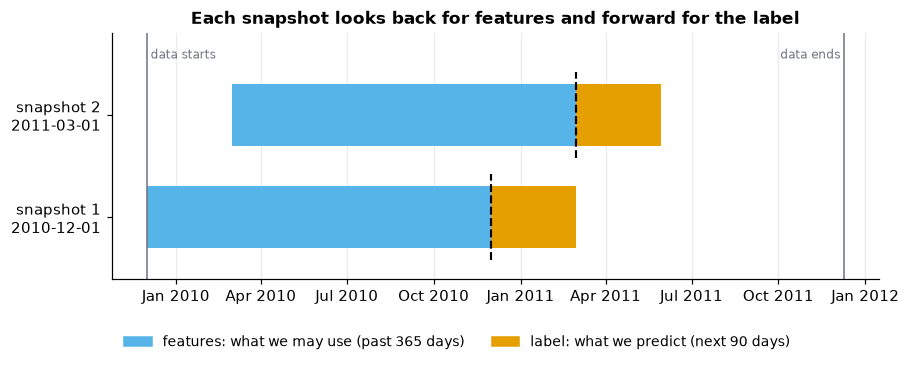

In [5]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9, 2.9))
rows = [pd.Timestamp("2010-12-01"), pd.Timestamp("2011-03-01")]
for i, c in enumerate(rows):
    ax.broken_barh([(mdates.date2num(c - LOOKBACK), 365)], (i - 0.3, 0.6), facecolors=style.SKY)
    ax.broken_barh([(mdates.date2num(c), 90)], (i - 0.3, 0.6), facecolors=style.ORANGE)
    ax.plot([mdates.date2num(c)] * 2, [i - 0.42, i + 0.42], color="black", ls="--", lw=1.4)
ax.axvline(mdates.date2num(sales["invoice_date"].min()), color=style.GREY, lw=1)
ax.axvline(mdates.date2num(sales["invoice_date"].max()), color=style.GREY, lw=1)
ax.text(mdates.date2num(sales["invoice_date"].min()) + 4, 1.55, "data starts", fontsize=8, color=style.GREY)
ax.text(mdates.date2num(sales["invoice_date"].max()) - 4, 1.55, "data ends", fontsize=8, color=style.GREY, ha="right")
ax.set_yticks([0, 1], ["snapshot 1\n2010-12-01", "snapshot 2\n2011-03-01"])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.set_ylim(-0.6, 1.8); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=style.SKY, label="features: what we may use (past 365 days)"), Patch(color=style.ORANGE, label="label: what we predict (next 90 days)")],
          loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2)
ax.set_title("Each snapshot looks back for features and forward for the label")
plt.show()

**Reading the chart.** The first snapshot (December 2010) is the earliest date with a full year of history, because the data begins in December 2009. Starting earlier would make every customer look "new" for a reason that is an artefact of where the data was cut off, not of their behaviour. We will meet that trap again when we split the data.

## What leakage looks like

Suppose someone builds a feature called *total number of invoices the customer ever placed*, using the whole file. It sounds harmless. Compare it with an honest version that stops at the snapshot date.

In [6]:
from sklearn.metrics import roc_auc_score

d = label.set_index("customer_id")
d["invoices_before_cutoff"] = past.groupby("customer_id").size().reindex(d.index)
d["invoices_all_time"] = inv.groupby("customer_id").size().reindex(d.index)     # includes the future!

auc = {c: roc_auc_score(d["y"], d[c]) for c in ["invoices_before_cutoff", "invoices_all_time"]}
print({k: round(v, 3) for k, v in auc.items()})
assert auc["invoices_all_time"] > auc["invoices_before_cutoff"] + 0.05

{'invoices_before_cutoff': 0.759, 'invoices_all_time': 0.869}


<div class="admonition danger">
<p class="admonition-title">The leaky feature looks like a breakthrough</p>
<p>The all-time count is much better at "predicting" the label, because it silently contains the very purchases we are trying to predict. A model using it would look brilliant in testing and be useless in production, where the future is not available. The honest feature is weaker, and <strong>weaker is the truth</strong>. If a score looks too good, suspect the timeline before you celebrate.</p>
</div>

## Choosing the metric: start from the decision

Accuracy is the default and the usual trap. Think about what the account managers will do: phone the **200 customers most at risk** each cycle (we assume a capacity of 200; the real number belongs to the business). So the question is not "is the classifier right on average" but *"of the 200 we call, how many were genuinely about to lapse, and how much were they worth?"*

First, the baseline of doing nothing clever. We rank customers by a one-line rule: **the longer since the last purchase, the more at risk.**

In [7]:
snap = retail.make_snapshot(sales, returns, cutoff)          # recency, frequency, monetary + label
assert snap["y"].sort_index().equals(label.set_index("customer_id")["y"].sort_index())   # the module agrees with our hand-built label
snap["lapse"] = 1 - snap["y"]                                  # the thing we want to catch
K = 200
base_lapse = snap["lapse"].mean()

rank = snap.sort_values("recency_days", ascending=False)       # most "at risk" first by the simple rule
top = rank.head(K)
precision_at_k = top["lapse"].mean()
print(f"base rate of lapsing:        {base_lapse:.1%}   (what random calling would achieve)")
print(f"precision@{K} of recency rule: {precision_at_k:.1%}")
print(f"lift over random calling:    {precision_at_k / base_lapse:.2f}x")
print(f"AUC of the recency rule:     {roc_auc_score(snap['lapse'], snap['recency_days']):.3f}")

base rate of lapsing:        63.1%   (what random calling would achieve)
precision@200 of recency rule: 83.0%
lift over random calling:    1.31x
AUC of the recency rule:     0.714


Even this trivial rule finds lapsers clearly more reliably than chance, so any model we build must clear a real bar, not an empty one. That is the job of a baseline.

But there is a catch the business will raise immediately: *are those 200 customers worth calling?* Let's measure the **past-year revenue of the customers we correctly flag**, compared with random calling and with the best possible 200.

In [8]:
rng = np.random.default_rng(0)
lapsers = snap[snap["lapse"] == 1]

revenue_rule   = top.loc[top["lapse"] == 1, "monetary"].sum()
revenue_oracle = lapsers.nlargest(K, "monetary")["monetary"].sum()       # if we knew the future perfectly
revenue_random = np.mean([snap.iloc[rng.choice(len(snap), K, replace=False)].query("lapse == 1")["monetary"].sum() for _ in range(500)])

print(f"past-year revenue of lapsers reached by calling 200 customers:")
print(f"  random calling : {revenue_random:>10,.0f}")
print(f"  recency rule   : {revenue_rule:>10,.0f}")
print(f"  perfect oracle : {revenue_oracle:>10,.0f}")
print(f"median past-year spend: top-200 by recency {top['monetary'].median():,.0f} vs all customers {snap['monetary'].median():,.0f}")
assert revenue_rule < revenue_random < revenue_oracle   # the claim made in the text below

past-year revenue of lapsers reached by calling 200 customers:
  random calling :    114,177
  recency rule   :     65,241
  perfect oracle :    998,036
median past-year spend: top-200 by recency 250 vs all customers 669


**What this shows.** On *count* the recency rule beats random calling, but on *revenue* it does **worse** than random: the customers who have been silent longest are mostly small spenders (compare the medians), so the rule hands the account managers the wrong people. The "perfect oracle" row is the ceiling, and it is many times higher than either: calling the right 200 would protect far more revenue. So the metric we should really care about is **revenue protected within a fixed call budget**, and a model that ranks by `probability of lapsing × value` could do much better than one that ranks by probability alone. We carry both numbers, *precision@k* and *revenue captured@k*, through the rest of the course.

<div class="admonition warning">
<p class="admonition-title">Prediction is not the same as influence</p>
<p>Our label records what customers <em>did</em>. It does not tell us whether a phone call <em>changes</em> what they do: some at-risk customers would have come back anyway, and some are gone whatever we say. Estimating the effect of the call is a different (causal, "uplift") problem. For now we use the score to <em>prioritise attention</em>, which is a legitimate use, and we keep the limitation in view.</p>
</div>

## What could still go wrong with this framing

- **Same person, two IDs.** A customer who re-registers looks like a lapse plus a new customer.
- **Seasonality inside the horizon.** A snapshot in September looks 90 days into the Christmas rush; one in June does not. The base rate will move, and we will see it move.
- **The end of the data.** A label window that runs past the last recorded date would count "no data yet" as "did not buy". We stop snapshots early enough to avoid it.
- **Survivorship.** We can only ever model customers who bought at least once; people who never bought are invisible here.

## Check yourself

<details class="question">
<summary>1. Why is each example a (customer, snapshot date) pair rather than just a customer?</summary>

Because the same customer can be safe at one date and at risk at another, and their features change with time. One row per customer would force a single, arbitrary "as of" moment and would hide how behaviour evolves. It also lets us build many examples from the same history, as long as we keep their time windows from leaking into each other (the next-but-one page).

</details>

<details class="question">
<summary>2. A teammate adds a feature, <code>days_until_next_order</code>, and reports an AUC of 0.99. What is wrong?</summary>

It is computed from the label window, so it contains the answer. A feature is only legitimate if it could be computed at the snapshot date in production. The test is always: *"on the cutoff date, could I have known this?"*

</details>

<details class="question">
<summary>3. On this snapshot about 37% of customers buy again. Why is roughly 63% accuracy not impressive?</summary>

Predicting "will **not** buy" for every customer is right for about 63% of them (one minus the base rate), so 63% is exactly what a model that learns nothing achieves, and it tells the account managers nothing about *who* to call. Always compare against the do-nothing baseline.

</details>

## Exercise

<details class="question">
<summary>Change the horizon to 60 days, then 120 days. Predict what happens to the base rate before you run it. Then check.</summary>

The base rate must **rise** as the horizon grows, because a longer window contains the shorter one, so any customer who buys within 60 days also buys within 120. Check it:

```python
for days in (60, 90, 120):
    fut = inv[(inv["date"] >= cutoff) & (inv["date"] < cutoff + pd.Timedelta(days=days))]["customer_id"].unique()
    print(days, round(pd.Series(active).isin(fut).mean(), 3))
```

Notice what you gain and lose: a longer horizon gives a more balanced label but a later, less actionable warning.

</details>

## Recap

- A prediction task needs six decisions: action, unit, population, event, horizon, snapshot. Write them down.
- Choose the horizon from the data, and say that it is a judgement.
- Features look only backward from the snapshot; the label looks only forward. A feature that could not be known at the cutoff is leakage, and leakage makes results look too good.
- Pick the metric from the decision. Our decision is a fixed call budget, so we track *precision@k* and *revenue captured@k*, and always compare with the base rate and a simple rule.

**Next:** *Data acquisition and validation*, which checks that the data deserves our trust before we use it.